<a href="https://colab.research.google.com/github/Park-wonil/BigdataPrac/blob/main/LanguageDevComparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
import os
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

/tmp/ipykernel_4652/2399737225.py:1: DtypeWarning: Columns (56,74,92,97,98,105,109,110,132,162,165) have mixed types. Specify dtype option on import or set low_memory=False.
  raw_df = pd.read_csv("https://media.githubusercontent.com/media/StackExchange/Survey/refs/heads/main/packages/archive/2025/results.csv")


(49191, 3)
Age
25-34 years old      16519
35-44 years old      13241
18-24 years old       9210
45-54 years old       6275
55-64 years old       2626
65 years or older      942
Prefer not to say      378
Name: count, dtype: int64


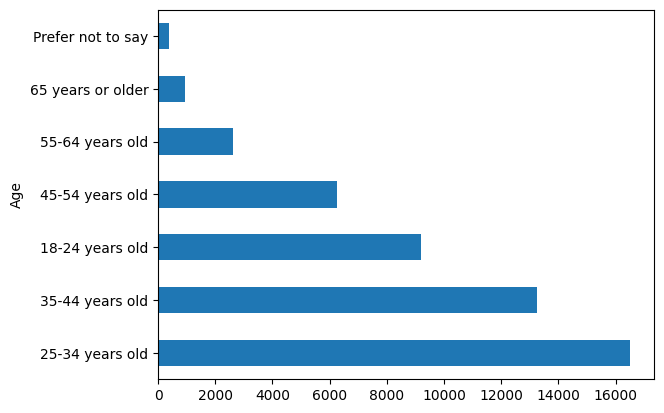

In [ ]:
raw_df = pd.read_csv("https://media.githubusercontent.com/media/StackExchange/Survey/refs/heads/main/packages/archive/2025/results.csv")
f_raw_df = raw_df[["Age","Country","LanguageHaveWorkedWith"]]
print(f_raw_df.shape)
age_df = f_raw_df["Age"].value_counts()#벨류카운트는 자동오름차순
age_df.plot.barh()
print(age_df)
#df.shape는 몇개행몇개열있는지확인
#3개의 col만 가져오기

In [ ]:
age_list = list(set(list(revised_df['Age'])))
age_df = pd.DataFrame()
for i in age_list:
  this_age_df = pd.DataFrame({"Age":i,"Count":[len(revised_df[revised_df['Age']==i])]})
  age_df = pd.concat([age_df,this_age_df])
  #groupby대신 노가다
print(age_df)

               Age  Count
0  35-44 years old  13241
               Age  Count
0  35-44 years old  13241
0  18-24 years old   9210
                 Age  Count
0    35-44 years old  13241
0    18-24 years old   9210
0  65 years or older    942
                 Age  Count
0    35-44 years old  13241
0    18-24 years old   9210
0  65 years or older    942
0    25-34 years old  16519
                 Age  Count
0    35-44 years old  13241
0    18-24 years old   9210
0  65 years or older    942
0    25-34 years old  16519
0    55-64 years old   2626
                 Age  Count
0    35-44 years old  13241
0    18-24 years old   9210
0  65 years or older    942
0    25-34 years old  16519
0    55-64 years old   2626
0    45-54 years old   6275
                 Age  Count
0    35-44 years old  13241
0    18-24 years old   9210
0  65 years or older    942
0    25-34 years old  16519
0    55-64 years old   2626
0    45-54 years old   6275
0  Prefer not to say    378
                 Age  Count
0 

In [ ]:
raw_df.shape
list(raw_df)
revised_df = raw_df[['Age','Country','LanguageHaveWorkedWith']]
revised_df#NULL값생김 제거해야함

,Age,Country,LanguageHaveWorkedWith
0,25-34 years old,Ukraine,Bash/Shell (all shells);Dart;SQL
1,25-34 years old,Netherlands,Java
2,35-44 years old,Ukraine,Dart;HTML/CSS;JavaScript;TypeScript
3,35-44 years old,Ukraine,Java;Kotlin;SQL
4,35-44 years old,Ukraine,C;C#;C++;Delphi;HTML/CSS;Java;JavaScript;Lua;P...
...,...,...,...
49186,18-24 years old,NaN,NaN
49187,45-54 years old,NaN,NaN
49188,35-44 years old,Italy,NaN
49189,25-34 years old,NaN,NaN


In [ ]:
df2 = raw_df.drop_duplicates() #중복된행 지워주는기능 dropna가 빈값지워주는기능
print(len(df2))

49191


In [ ]:
age_df = revised_df.groupby('Age').size().reset_index(name='count')
#나이별로.size는 총 몇개씩 들어있느지 개수를샘 reset은 행열표로변환 세로열제목을count
print(age_df)
age_df = age_df.set_index('Age') #새로운기준
print(age_df)

                 Age  count
0    18-24 years old   9210
1    25-34 years old  16519
2    35-44 years old  13241
3    45-54 years old   6275
4    55-64 years old   2626
5  65 years or older    942
6  Prefer not to say    378
                   count
Age                     
18-24 years old     9210
25-34 years old    16519
35-44 years old    13241
45-54 years old     6275
55-64 years old     2626
65 years or older    942
Prefer not to say    378


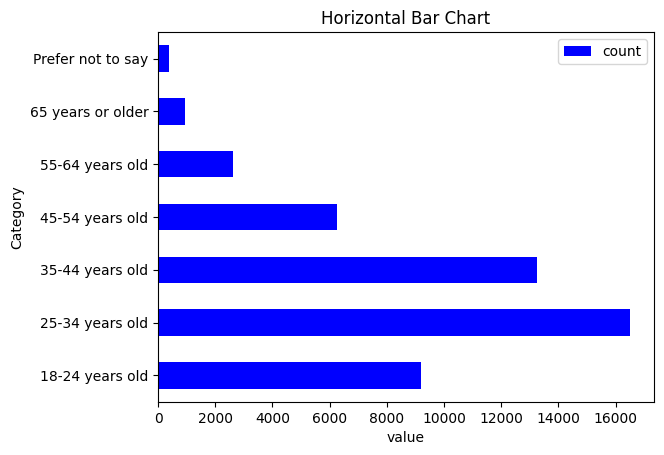

In [ ]:
age_order = [
    "18-24 years old",
    "25-34 years old",
    "35-44 years old",
    "45-54 years old",
    "55-64 years old",
    "65 years or older",
    "Prefer not to say"
]
#리스트로 구분해야될 리스트 나타내기

age_counts = raw_df.groupby("Age").size().reindex(age_order)
 #.size().redindex(age_order)
age_counts.plot.barh(color='blue',label='count')
plt.title('Horizontal Bar Chart')
plt.xlabel('value')
plt.ylabel('Category')
plt.legend()
plt.show()

#연령별 개발자비율

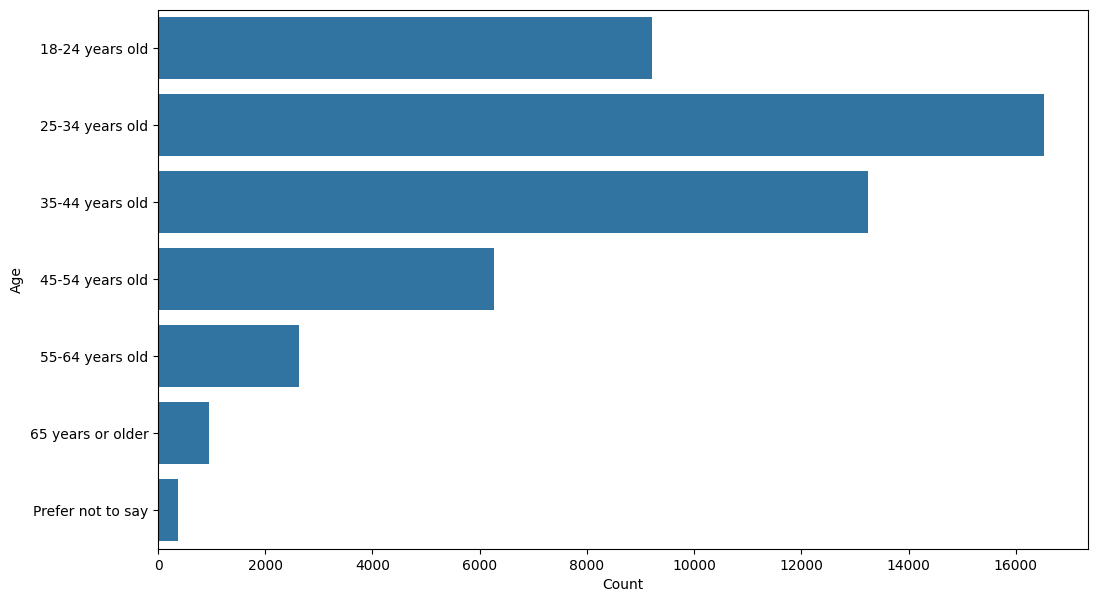

In [ ]:
plt.figure(figsize=(12, 7))

sns.barplot(
    x=age_counts.values,
    y=age_counts.index
)

plt.xlabel("Count")
plt.ylabel("Age")

plt.show()

#국가별 개발자비율


<Axes: >

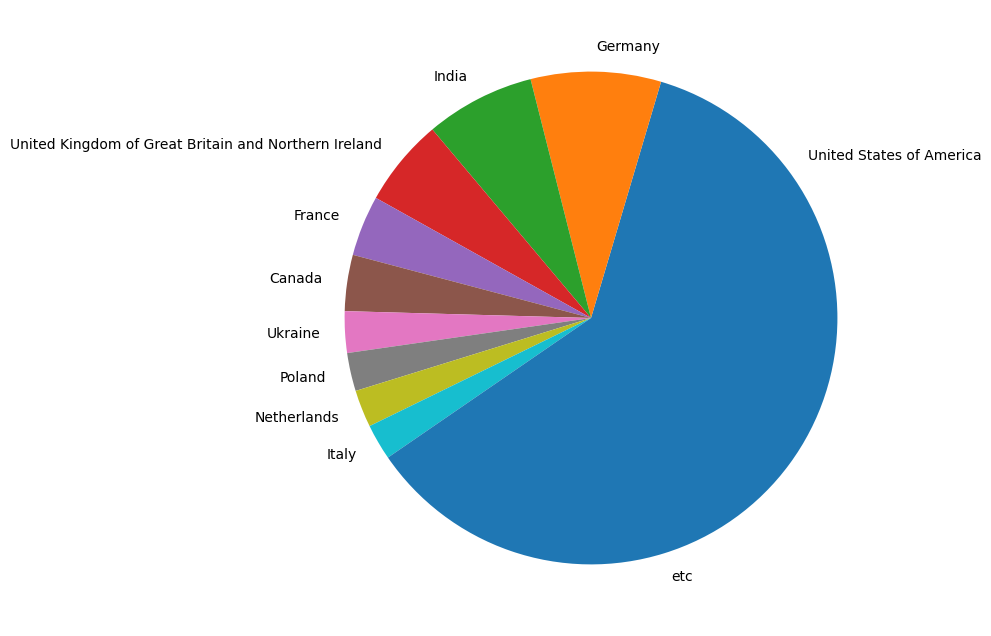

In [ ]:
country_counts = raw_df["Country"].value_counts()
top10 = country_counts.nlargest(10)#상위10개
etc = country_counts[10:].sum()#나머지11등부터


country_pie = pd.concat([
    top10,
    pd.Series({"etc": etc})
])
#concat말고 행으로이어붙이기

country_pie.plot.pie(
    figsize =(8,8)
)


#개발자 언어사용 비율

<Axes: ylabel='count'>

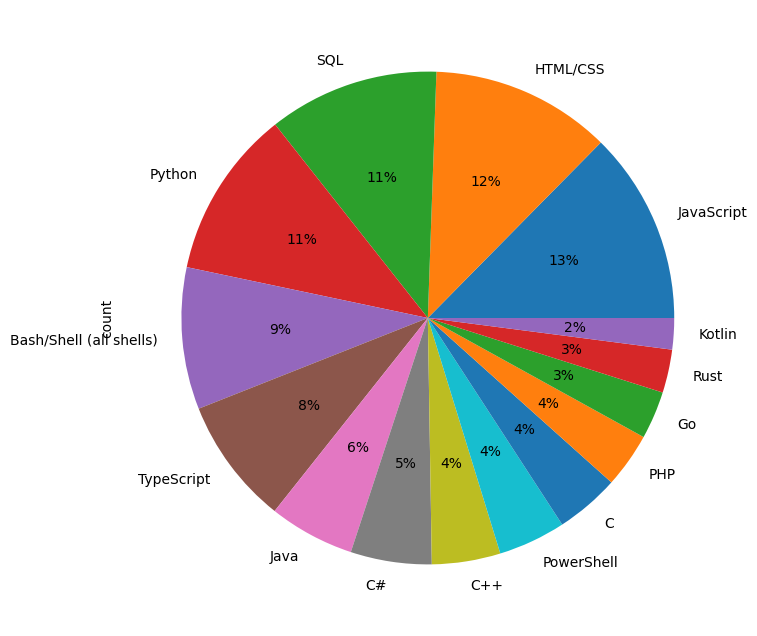

In [ ]:
language_counts = (
    raw_df["LanguageHaveWorkedWith"]
    .dropna()
    .str.split(";")
    .explode()
    .value_counts()
)
top15 = language_counts.nlargest(15)
top15.plot.pie(autopct = "%.0f%%",
               figsize=(8, 8)
               )

In [ ]:
a=revised_df['LanguageHaveWorkedWith'].str.split(';')#리스트를 ;로쪼개줘
a.explode('LaguageHaveWorkedWith') #데이터를 (리스트)각각 한줄씩 따로따로 펼쳐주는ㄱ기능

,LanguageHaveWorkedWith
0,Bash/Shell (all shells)
1,Dart
2,SQL
3,Java
4,Dart
...,...
212099,NaN
212100,NaN
212101,NaN
212102,NaN
